# 6 · Language model training, prompting, and decoding

**Question.** What is learned in the weights, and what changes when we provide a prompt?

[Download the executed notebook](https://chikuang.github.io/teaching/genai/notebooks/06-language-models.ipynb)

**Python support:** Review [A.6–A.8: classes, updates and tensor dimensions](https://chikuang.github.io/teaching/genai/appendices/a-python-pytorch.html#a-6-what-a-model-class-means). A.12 explains comprehensions, decorators and `**settings`. Use **Show all code** while working.


A language model specifies conditional token distributions. A prompt supplies conditioning information; a decoder turns probabilities into a sequence. These are three different objects. We will train a small character model on an explicitly artificial sentence distribution, evaluate it on held-out combinations, and sample it under several decoding rules.

**Prerequisites:** Chapters 1–5. **Outcomes:** align shifted targets; distinguish teacher forcing from generation; evaluate held-out log loss; implement temperature, top-k, and nucleus sampling. We continue the exact `DecoderBlock` and `TinyDecoder` from Chapter 5, now fitting them on training text and selecting a checkpoint on validation text. [Appendix A](https://chikuang.github.io/teaching/genai/appendices/a-python-pytorch.html) explains the Python syntax and tensor operations step by step.

## Pipeline and framework

![Training fits and selects model parameters from shifted token targets; generation repeatedly predicts, decodes and appends the next token using frozen parameters. Remember: training changes weights; decoding chooses the next token.](https://chikuang.github.io/teaching/genai/_static/diagrams/06-language-model.png)

The output of training is a **parameterized conditional distribution**. The output of decoding is a sequence drawn or selected using that distribution. Prompting supplies a prefix; it does not run an optimizer. The same decoder architecture from Chapter 5 now learns its weights. Chapter 5 checked the forward calculation and causality; this chapter checks prediction on held-out sequences.

| Stage | Artifact | Question to ask |
|:--|:--|:--|
| Construct examples | Sequences, shifted targets, and padding mask | Which positions contribute to the likelihood? |
| Fit and select | Training trace and validation-selected checkpoint | Was the test split excluded from all choices? |
| Score | Token losses under the frozen checkpoint | Are tokenization, special symbols, and averaging conventions comparable? |
| Decode | Prompt, decoding rule, seed, stop rule, output tokens | Did a change alter model probabilities or only the sampling procedure? |

Inside the generation loop, the newly appended token becomes part of the next prefix. Stop on an end token or an explicit maximum length. A key/value cache in a transformer can avoid recomputing earlier states; it is an implementation optimization, not a new statistical estimator. The experiment below records unchanged weights to make the training/prompting distinction concrete.

## 6.1 · The likelihood and the training distribution

The autoregressive factorization is

$$
p_\theta(x_{1:T})=\prod_{t=1}^T p_\theta(x_t\mid x_{<t}),\qquad
\widehat L=-\frac{\sum_s\sum_t\log p_\theta(x_{st}\mid x_{s,<t})}{\sum_s T_s}.
$$

Equation [(6.1)](https://chikuang.github.io/teaching/genai/chapters/06-language-models.html#equation-eq-lm-objective) applies the chain rule from Equation [(1.8)](https://chikuang.github.io/teaching/genai/chapters/01-probability-to-genai.html#equation-eq-chain-rule) to training sequences. Its token-weighted loss gives longer sequences more weight. A mean of per-sequence losses answers a different question. Always state the averaging unit. During teacher forcing, each prefix contains observed training tokens. During generation, later prefixes contain sampled tokens, so mistakes can change the distribution of future inputs.

Our corpus enumerates combinations of four subjects, four verbs, and four objects. We hold out complete combinations before making batches. This avoids overlapping-window leakage, but it remains a tiny, deliberately repetitive grammar; it is not evidence about unrestricted English.

In [1]:
import copy
import math
import itertools
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.set_num_threads(1)
torch.manual_seed(6)
rng = np.random.default_rng(6)
sentences = ['the ' + s + ' ' + v + ' ' + o + '.'
             for s, v, o in itertools.product(
                 ['model', 'student', 'network', 'agent'],
                 ['learns', 'studies', 'explains', 'predicts'],
                 ['data', 'language', 'patterns', 'uncertainty'])]
order = rng.permutation(len(sentences))
train_text = [sentences[i] for i in order[:42]]
valid_text = [sentences[i] for i in order[42:53]]
test_text = [sentences[i] for i in order[53:]]
# The alphabet is specified in advance, not learned from the test sentences.
chars = ['<pad>'] + list('^\n abcdefghijklmnopqrstuvwxyz.')
char_id = {c: i for i, c in enumerate(chars)}

def batch(texts):
    encoded = [[char_id[c] for c in '^' + s + '\n'] for s in texts]
    result = torch.zeros(len(texts), max(map(len, encoded)), dtype=torch.long)
    for i, row in enumerate(encoded):
        result[i, :len(row)] = torch.tensor(row)
    return result[:, :-1], result[:, 1:]

Xtr, Ytr = batch(train_text)
Xva, Yva = batch(valid_text)
Xte, Yte = batch(test_text)
print('Split sizes:', len(train_text), len(valid_text), len(test_text))
print('Training input and target shape:', tuple(Xtr.shape), tuple(Ytr.shape))

Split sizes: 42 11 11
Training input and target shape: (42, 34) (42, 34)


`^` marks the beginning of a sequence, newline marks its end, and zero is padding. Padding positions are excluded from the loss. The causal attention mask prevents right-padding after a sentence from affecting its earlier predictions. We do not left-pad: earlier padding would require an additional key-padding mask.

### Make the padding mask part of the objective

Let $z_{stj}$ be the logit for token $j$ at prediction position $t$ of sequence $s$, $y_{st}$ its next-token target, and $m_{st}\in\{0,1\}$ indicate a non-padding target. With $N_{\mathrm{tok}}=\sum_{s,t}m_{st}>0$,

$$
\widehat L(\theta)=\frac1{N_{\mathrm{tok}}}
\sum_{s,t}m_{st}\left[\log\sum_{j=1}^{V}e^{z_{stj}}-z_{st,y_{st}}\right].
$$

Equation [(6.2)](https://chikuang.github.io/teaching/genai/chapters/06-language-models.html#equation-eq-masked-token-loss) is what cross-entropy with ignored padding computes; it makes the valid-token denominator in Equation [(6.1)](https://chikuang.github.io/teaching/genai/chapters/06-language-models.html#equation-eq-lm-objective) explicit. In this corpus, the beginning marker is input context and the end marker is a genuine prediction target. Ignoring a padding target removes that **position's loss**; it does not automatically remove the padding class from the softmax denominator at other positions. The sampler below separately forbids generating padding and a new beginning marker.

> **Example 6.1 · The loss denominator defines the weighting**
>
> **Setup.** Response A has two valid target-token losses, $0.2$ and $0.4$. Response B has four valid losses, all $1.0$. Pad A with two ignored positions to batch the responses.
>
> **Work it through.** Equation [(6.2)](https://chikuang.github.io/teaching/genai/chapters/06-language-models.html#equation-eq-masked-token-loss) gives the token-weighted mean $(0.2+0.4+4)/6\approx0.7667$ nats. Averaging response means instead gives $[(0.2+0.4)/2+1]/2=0.65$. Setting padded losses to zero but dividing by all eight array positions incorrectly gives $4.6/8=0.575$.
>
> **What this shows.** A mask must affect both the summed loss and its denominator. Token weighting gives the longer response more influence; equal response weighting is a different declared objective. Perplexity inherits whichever averaging convention was used, so these three numbers are not interchangeable evaluations.

## 6.2 · Fit a small conditional model

We reuse the two classes from Chapter 5 verbatim below so this downloaded notebook can run independently. The vocabulary now contains the character alphabet. The maximum context is 96 positions, longer than every training sentence. Width 24 still splits into three heads of width 8; this is the same architecture, fitted on a different task.

In [2]:
class DecoderBlock(nn.Module):
    def __init__(self, width=24, heads=3):
        super().__init__()
        assert width % heads == 0
        self.heads = heads
        self.head_width = width // heads
        self.norm1 = nn.LayerNorm(width)
        self.norm2 = nn.LayerNorm(width)
        self.qkv = nn.Linear(width, 3 * width)
        self.project = nn.Linear(width, width)
        self.ffn = nn.Sequential(nn.Linear(width, 4 * width), nn.GELU(),
                                 nn.Linear(4 * width, width))

    def forward(self, x):
        B, T, D = x.shape
        normalized = self.norm1(x)
        # Split feature coordinates, then expose a separate head axis.
        q, k, v = self.qkv(normalized).chunk(3, dim=-1)
        q, k, v = [a.reshape(B, T, self.heads, self.head_width)
                    .transpose(1, 2) for a in (q, k, v)]
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.head_width)
        allowed = torch.ones(T, T, dtype=torch.bool, device=x.device).tril()
        weights = torch.softmax(scores.masked_fill(~allowed, -torch.inf), dim=-1)
        mixed = (weights @ v).transpose(1, 2).contiguous().reshape(B, T, D)
        x = x + self.project(mixed)
        return x + self.ffn(self.norm2(x))

The block maps `(batch, time, width)` back to the same shape. The wrapper below first looks up token and position vectors, then maps the final states to one logit per vocabulary item. `self` refers to this particular model instance; submodules assigned to it register their trainable parameters.

In [3]:
class TinyDecoder(nn.Module):
    def __init__(self, vocab_size=12, width=24, max_length=32):
        super().__init__()
        self.max_length = max_length
        self.token = nn.Embedding(vocab_size, width)
        self.position = nn.Embedding(max_length, width)
        self.block = DecoderBlock(width=width, heads=3)
        self.final_norm = nn.LayerNorm(width)
        self.head = nn.Linear(width, vocab_size)

    def forward(self, ids):
        T = ids.shape[1]
        if T > self.max_length:
            raise ValueError('Sequence exceeds the position table')
        positions = torch.arange(T, device=ids.device)
        x = self.token(ids) + self.position(positions)
        return self.head(self.final_norm(self.block(x)))

Constructing a model allocates its parameters. Calling `model(ids)` invokes `forward`; these are different operations.

In [4]:
model = TinyDecoder(vocab_size=len(chars), width=24, max_length=96)
optimizer = torch.optim.Adam(model.parameters(), lr=0.008)
def log_loss(x, y):
    return nn.functional.cross_entropy(model(x).reshape(-1, len(chars)),
                                        y.reshape(-1), ignore_index=0)

Before looping, identify three state variables: `history` stores scalar diagnostics, `best` is the smallest validation loss so far, and `checkpoint` is a copied parameter snapshot. No test observation participates in this choice.

Best validation log loss: 0.536


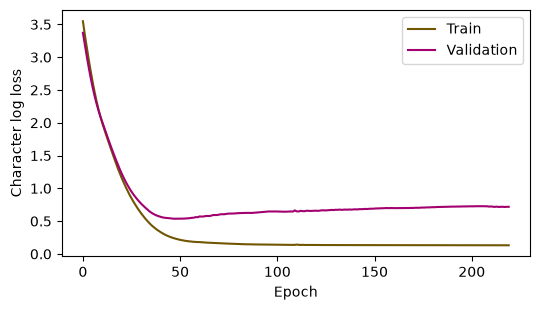

In [5]:
history, best, checkpoint = [], float('inf'), None
for epoch in range(220):
    model.train()
    optimizer.zero_grad()
    loss = log_loss(Xtr, Ytr)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    model.eval()
    with torch.no_grad():
        validation = log_loss(Xva, Yva).item()
    history.append((loss.item(), validation))
    if validation < best:
        best, checkpoint = validation, copy.deepcopy(model.state_dict())
model.load_state_dict(checkpoint)
print('Best validation log loss:', round(best, 3))
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(np.asarray(history)[:, 0], label='Train', color='#705600')
ax.plot(np.asarray(history)[:, 1], label='Validation', color='#a2006e')
ax.set(xlabel='Epoch', ylabel='Character log loss')
ax.legend()
plt.tight_layout()
plt.show()

Read the update as six operations: `zero_grad()` clears the previous derivative; `model(Xtr)` computes logits; cross-entropy compares them with shifted targets; `backward()` computes derivatives; clipping bounds their norm; `step()` changes parameters. `reshape(-1, len(chars))` pools batch and time into the observation axis while preserving the vocabulary axis. `ignore_index=0` removes padded target positions from both sum and denominator.

Validation runs with gradients disabled. `deepcopy(model.state_dict())` takes a snapshot; assigning the live dictionary alone would let later updates change the saved weights. We fix 220 updates and the learning rate in advance; the test set cannot select either. Appendix A builds this loop one operation at a time.

Gradient clipping limits the gradient norm; it does not change the data split or turn a poor model into a valid estimator. The checkpoint is selected by validation loss, and only then evaluated on test text.

## 6.3 · Evaluate likelihood against a simple baseline

In [6]:
counts = torch.bincount(Ytr[Ytr != 0], minlength=len(chars)).float() + 1
unigram = counts / counts.sum()
with torch.no_grad():
    neural_loss = log_loss(Xte, Yte).item()
    baseline_loss = -torch.log(unigram[Yte[Yte != 0]]).mean().item()
print(f'Unigram test loss: {baseline_loss:.3f}')
print(f'Neural test loss: {neural_loss:.3f}')
print(f'Character perplexity: {np.exp(neural_loss):.3f}')

Unigram test loss: 2.879
Neural test loss: 0.395
Character perplexity: 1.485


Perplexity is the exponential of mean token log loss. It is comparable here because both systems use the same alphabet and test targets. It is not directly comparable with a subword model's perplexity. A low score on this grammar does not establish factual accuracy, useful reasoning, or performance under a different language distribution.

## 6.4 · Decoding changes the sampling distribution

Temperature $T>0$ maps logits $z_j$ to probabilities proportional to $\exp(z_j/T)$. Top-k retains the k largest logits. Nucleus (top-p) sampling retains the smallest descending-probability prefix whose total mass reaches p, then renormalizes. We apply temperature, then top-k if requested, then top-p. Specifying this order matters when combining filters.

### Define the distribution after each decoding choice

Use $\tau>0$ for temperature here, reserving $T$ for sequence length, and let $\mathcal A$ exclude forbidden special tokens. If top-k is active, let $K$ be the $k$ largest-logit eligible tokens (or all eligible tokens if fewer exist); otherwise $K=\mathcal A$. Temperature followed by top-k gives

$$
r_j=\frac{\mathbf1\{j\in K\}e^{z_j/\tau}}
{\sum_{v\in K}e^{z_v/\tau}}.
$$

Sort the probabilities from Equation [(6.3)](https://chikuang.github.io/teaching/genai/chapters/06-language-models.html#equation-eq-top-k) as $r_{(1)}\ge r_{(2)}\ge\cdots$. For nucleus mass $\rho\in(0,1]$, keep the shortest prefix $S$ ending at $m^*=\min\{m:\sum_{j=1}^{m}r_{(j)}\ge\rho\}$. The final sampling law is

$$
q_j=\frac{r_j\mathbf1\{j\in S\}}{\sum_{v\in S}r_v}.
$$

The set $S$ in Equation [(6.4)](https://chikuang.github.io/teaching/genai/chapters/06-language-models.html#equation-eq-nucleus) includes the token that first reaches the threshold, exactly as `cumsum - sorted_p` does below. The denominator uses the distribution **after** top-k, so changing filter order changes $q$. A fixed tie-breaking rule is needed at equal scores. The resulting sequence law is the product of these modified conditionals until the end token or length limit; its log likelihood is generally different from the original model's test likelihood. Greedy selection takes an argmax instead of drawing from $q$.

In [7]:
def decoding_probabilities(logits, temperature=1.0, top_k=None, top_p=1.0):
    if temperature <= 0 or not 0 < top_p <= 1:
        raise ValueError('Require temperature > 0 and 0 < top_p <= 1')
    z = logits.clone() / temperature
    z[0] = -torch.inf                 # never generate padding
    z[char_id['^']] = -torch.inf       # no new beginning marker
    if top_k is not None:
        if top_k < 1:
            raise ValueError('top_k must be positive')
        keep = torch.topk(z, min(top_k, len(z))).indices
        filtered = torch.full_like(z, -torch.inf)
        filtered[keep] = z[keep]
        z = filtered
    probabilities = torch.softmax(z, dim=-1)
    sorted_p, sorted_ids = torch.sort(probabilities, descending=True)
    # Keep the token that first crosses the requested cumulative mass.
    remove = sorted_p.cumsum(0) - sorted_p >= top_p
    probabilities[sorted_ids[remove]] = 0
    return probabilities / probabilities.sum()

@torch.no_grad()
def generate(prompt='the ', seed=1, greedy=False, **settings):
    model.eval()
    ids = [char_id[c] for c in '^' + prompt]
    generator = torch.Generator().manual_seed(seed)
    stop_reason = 'length_limit'
    for _ in range(60):
        if len(ids) > model.max_length:
            stop_reason = 'context_limit'
            break
        logits = model(torch.tensor([ids]))[0, -1]
        probabilities = decoding_probabilities(logits, **settings)
        next_id = int(probabilities.argmax()) if greedy else int(
            torch.multinomial(probabilities, 1, generator=generator))
        if chars[next_id] == '\n':
            stop_reason = 'end_token'
            break
        ids.append(next_id)
    return {'text': ''.join(chars[i] for i in ids[1:]), 'stop_reason': stop_reason}

print('Greedy:', generate(greedy=True))
for temperature in [0.6, 1.0, 1.4]:
    for seed in [1, 2]:
        print(temperature, seed, generate(seed=seed, temperature=temperature, top_p=0.95))

Greedy: {'text': 'the agent learns panguage.', 'stop_reason': 'end_token'}
0.6 1 {'text': 'the network explains dagerns.', 'stop_reason': 'end_token'}
0.6 2 {'text': 'the network learns uncertainty.', 'stop_reason': 'end_token'}
1.0 1 {'text': 'the network explains dage.', 'stop_reason': 'end_token'}
1.0 2 {'text': 'the network learns uncertainty.', 'stop_reason': 'end_token'}
1.4 1 {'text': 'the networletuns datta.', 'stop_reason': 'end_token'}
1.4 2 {'text': 'the network odedictt panege.', 'stop_reason': 'end_token'}


Read the generated strings, including malformed ones. Higher sampling entropy does not imply more useful diversity. Greedy decoding optimizes a local choice and need not find the globally most probable sequence. Sampling settings should be selected for a specified use case on development prompts, then evaluated on new prompts and repeated seeds.

> **Example 6.2 · Filtering order can change what gets sampled**
>
> **Setup.** Four tokens have probabilities $(0.50,0.30,0.15,0.05)$. Use top-$k$ with $k=2$ and nucleus threshold $p=0.60$, with no temperature change.
>
> **Work it through.** Applying top-$k$ first retains the first two tokens and renormalizes to $(0.625,0.375)$. The first token alone now crosses the nucleus threshold, so top-$p$ leaves probability one on that token. Reversing the order gives a different result: the original first token has mass $0.50<0.60$, so nucleus selection retains the first two tokens, producing $(0.625,0.375)$. Top-$k$ then removes nothing further.
>
> **What this shows.** Equations [(6.3)](https://chikuang.github.io/teaching/genai/chapters/06-language-models.html#equation-eq-top-k) and [(6.4)](https://chikuang.github.io/teaching/genai/chapters/06-language-models.html#equation-eq-nucleus) define successive distributions. Record the order and include the token that first reaches or crosses the cumulative threshold. Identical numerical settings can otherwise describe different samplers.

## 6.5 · Prompting versus parameter estimation

A prompt changes the conditioning sequence while leaving fitted weights fixed. Examples in a prompt can demonstrate a pattern, but the ordinary inference call does not invoke the optimizer. Our tiny grammar model was never trained to follow instructions, so asking it to “explain Bayes' theorem” is a distribution-shift experiment, not a fair instruction-following test.

In [8]:
before = {name: value.detach().clone() for name, value in model.named_parameters()}
print('In-domain prefix:', generate(prompt='the agent '))
print('Out-of-domain prefix:', generate(prompt='explain '))
assert all(torch.equal(before[name], value) for name, value in model.named_parameters())
print('Generation left all model parameters unchanged.')

In-domain prefix: {'text': 'the agent learns data.', 'stop_reason': 'end_token'}
Out-of-domain prefix: {'text': 'explain let learta.', 'stop_reason': 'end_token'}
Generation left all model parameters unchanged.


Pretraining estimates a broad conditional model. Supervised instruction tuning changes parameters using instruction/response examples. Retrieval supplies external context. A system can combine all three. None is a substitute for checking whether the output answers the intended question using valid evidence.


### Coding and experiment practice · Compare decoding distributions

**1. Predict before running.** Can changing temperature improve the already-computed test likelihood without changing any model weight?

**2. Implement and check.** Use the trained decoder, three temperatures and the same ten seeds. Store each result before computing a summary so malformed or truncated strings remain inspectable. The code below is a **worked example**. For independent work, download [Assignment 06](https://chikuang.github.io/teaching/genai/_static/assignments/06-student.ipynb), which has an empty implementation, separate acceptance fixtures and a new transfer task. Attempt it before opening the separate solution file.

In [9]:
def grammar_hit(generation, allowed_sentences):
    return (generation['stop_reason'] == 'end_token'
            and generation['text'] in allowed_sentences)

assert grammar_hit({'text': sentences[0], 'stop_reason': 'end_token'}, set(sentences))
assert not grammar_hit({'text': sentences[0], 'stop_reason': 'length_limit'}, set(sentences))
assert not grammar_hit({'text': 'not a sentence in this grammar', 'stop_reason': 'end_token'}, set(sentences))
decoding_rows = []
for temperature in [0.6, 1.0, 1.4]:
    for seed in range(10):
        output = generate(seed=seed, temperature=temperature, top_p=0.95)
        decoding_rows.append({'temperature': temperature, 'seed': seed,
                              **output, 'grammar_hit': grammar_hit(output, set(sentences))})
assert len(decoding_rows) == 30
for temperature in [0.6, 1.0, 1.4]:
    rows = [row for row in decoding_rows if row['temperature'] == temperature]
    print(temperature, 'hits:', sum(row['grammar_hit'] for row in rows),
          'distinct:', len({row['text'] for row in rows}),
          'truncated:', sum(row['stop_reason'] != 'end_token' for row in rows))
print('First retained record:', decoding_rows[0])

0.6 hits: 7 distinct: 10 truncated: 0
1.0 hits: 5 distinct: 9 truncated: 0
1.4 hits: 0 distinct: 10 truncated: 0
First retained record: {'temperature': 0.6, 'seed': 0, 'text': 'the student learns uncertainty.', 'stop_reason': 'end_token', 'grammar_hit': True}


The outer loop selects a decoding distribution; the inner loop samples ten trajectories. `**output` copies the text and stop reason into a larger dictionary. Grammar membership and diversity answer different questions. The known grammar is a diagnostic specification, not training data newly supplied to the model.

**3. Extend one factor.** Choose a new prefix before evaluating, keep the same seed grid, and compare truncation, grammar membership and diversity. Preserve all 30 records. Test likelihood remains the score of the unchanged fitted conditionals.

**Submission and rubric.** Submit the function and its checks, the requested comparison table, and three sentences naming the target, interpreting the result, and limiting the claim. Passing a deterministic fixture verifies the stated calculation; a favorable stochastic result is not required. Retain unexpected results and diagnose them rather than changing seeds until a preferred ranking appears.


## 6.6 · Exercises

1. **Teacher forcing:** why can the training loss be small while generated sequences drift?
2. **Nucleus filter:** for probabilities $(0.5,0.3,0.2)$ and $p=0.6$, what survives?
3. **Temperature:** show that the log odds between two tokens become $(z_i-z_j)/T$.
4. **Test protocol:** why not select temperature by reporting the best of 100 test generations?
5. **Loss unit:** when do token-averaged and sequence-averaged losses agree?


<details><summary>Worked solutions — attempt the questions first</summary>

**1.** training conditions on observed prefixes; generation conditions on the model's own earlier samples. A locally plausible mistake can move later inputs away from the training distribution.

**2.** the first two tokens, because their cumulative mass first exceeds 0.6. Renormalized probabilities are $(0.625,0.375,0)$.

**3.** take the logarithm of the ratio of their softmax probabilities; the normalization cancels. Decreasing positive temperature magnifies existing log-odds differences.

**4.** selection uses the test outcomes and changes the procedure being evaluated. Fix the selection rule on development prompts and evaluate its full distribution, including failed samples.

**5.** they agree when sequence lengths are equal, or accidentally when the relevant weighted and unweighted averages coincide. With varying lengths they generally estimate different targets.

</details>

## 6.7 · Further reading and transition

The [transformer paper](https://arxiv.org/abs/1706.03762) motivates the architecture reused from Chapter 5. [Appendix B](https://chikuang.github.io/teaching/genai/appendices/b-real-llm-systems.html) moves from our trained toy decoder to an actual pretrained instruction model, including chat templates and bounded generation. A GRU is a possible architecture-comparison exercise, not a prerequisite for this chapter. Next, [Chapter 7](https://chikuang.github.io/teaching/genai/chapters/07-latent-variable-models.html) constructs distributions through latent variables instead of a token-by-token factorization.


**Choose the next route.** For LLM/RAG/Agent work, complete [live lab 1](https://chikuang.github.io/teaching/genai/appendices/c-guided-live-labs.html#c-1-see-the-complete-first-call) now, then continue to [Chapter 10](https://chikuang.github.io/teaching/genai/chapters/10-rag.html). For other generative families, continue to Chapter 7. Both routes build on the distinction between fitted conditionals and the decoding distribution established here.